In [1]:
# 따릉이 대여 예측 미니 프로젝트 (시계열 데이터 회귀 예측)

In [2]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
import koreanize_matplotlib # 한글깨짐 방지
plt.rcParams['axes.unicode_minus'] = False # 마이너스 기호 깨짐 방지

In [3]:
df = pd.read_csv('../../data/SeoulBikeData.csv', encoding='latin1') # 온도 기호(°) 때문에 latin1
df

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,30/11/2018,1003,19,4.2,34,2.6,1894,-10.3,0.0,0.0,0.0,Autumn,No Holiday,Yes
8756,30/11/2018,764,20,3.4,37,2.3,2000,-9.9,0.0,0.0,0.0,Autumn,No Holiday,Yes
8757,30/11/2018,694,21,2.6,39,0.3,1968,-9.9,0.0,0.0,0.0,Autumn,No Holiday,Yes
8758,30/11/2018,712,22,2.1,41,1.0,1859,-9.8,0.0,0.0,0.0,Autumn,No Holiday,Yes


In [4]:
df.columns

Index(['Date', 'Rented Bike Count', 'Hour', 'Temperature(°C)', 'Humidity(%)',
       'Wind speed (m/s)', 'Visibility (10m)', 'Dew point temperature(°C)',
       'Solar Radiation (MJ/m2)', 'Rainfall(mm)', 'Snowfall (cm)', 'Seasons',
       'Holiday', 'Functioning Day'],
      dtype='object')

In [5]:
df = df.rename(columns={
    'Rented Bike Count': 'bikes', # 자전거 대여 건수
    'Temperature(°C)': 'temp',    # 기온
    'Humidity(%)': 'humidity',    # 습도
    'Rainfall(mm)': 'rain'        # 강수량
})

In [6]:
df.columns

Index(['Date', 'bikes', 'Hour', 'temp', 'humidity', 'Wind speed (m/s)',
       'Visibility (10m)', 'Dew point temperature(°C)',
       'Solar Radiation (MJ/m2)', 'rain', 'Snowfall (cm)', 'Seasons',
       'Holiday', 'Functioning Day'],
      dtype='object')

In [7]:
# 예 : '01/12/2017' (일/월/년) 형식의 글자 --> 2017-12-01 (실제 날짜 datetime)
date = pd.to_datetime(df['Date'], format="%d/%m/%Y")

In [8]:
# 예 : 13 --> 13시간
hour = pd.to_timedelta(df['Hour'], unit='h')

In [9]:
# 예 : 2017-12-01 + 13시간 --> 2017-12-01 13:00:00
df['datetime'] = date + hour

In [10]:
df = df.set_index('datetime')
df = df.sort_index() # 정렬
df

,Date,bikes,Hour,temp,humidity,Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),rain,Snowfall (cm),Seasons,Holiday,Functioning Day
datetime,,,,,,,,,,,,,,
2017-12-01 00:00:00,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2017-12-01 01:00:00,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2017-12-01 02:00:00,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
2017-12-01 03:00:00,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2017-12-01 04:00:00,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2018-11-30 19:00:00,30/11/2018,1003,19,4.2,34,2.6,1894,-10.3,0.0,0.0,0.0,Autumn,No Holiday,Yes
2018-11-30 20:00:00,30/11/2018,764,20,3.4,37,2.3,2000,-9.9,0.0,0.0,0.0,Autumn,No Holiday,Yes
2018-11-30 21:00:00,30/11/2018,694,21,2.6,39,0.3,1968,-9.9,0.0,0.0,0.0,Autumn,No Holiday,Yes


In [11]:
print(f"데이터: {len(df):,}행 x {len(df.columns)}열")

데이터: 8,760행 x 14열


In [12]:
print("시작:", df.index.min())
print("종료:", df.index.max())

시작: 2017-12-01 00:00:00
종료: 2018-11-30 23:00:00


In [13]:
print(f"전체 결측값: {df.isna().sum().sum():,}개")

전체 결측값: 0개


In [14]:
display(df[ ['bikes', 'Hour', 'temp', 'humidity', 'rain'] ].head())

,bikes,Hour,temp,humidity,rain
datetime,,,,,
2017-12-01 00:00:00,254,0,-5.2,37,0.0
2017-12-01 01:00:00,204,1,-5.5,38,0.0
2017-12-01 02:00:00,173,2,-6.0,39,0.0
2017-12-01 03:00:00,107,3,-6.2,40,0.0
2017-12-01 04:00:00,78,4,-6.0,36,0.0


In [15]:
split_position = int( len(df) * 0.8 ) # 80% 지점
split_time = df.index[ split_position ]
eda = df.loc[ df.index < split_time ].copy() # train

In [16]:
eda = eda[ eda['Functioning Day'] == 'Yes' ].copy()

In [17]:
eda['요일'] = eda.index.dayofweek # 월요일=0, 일요일=6

In [18]:
eda['구분'] = '평일'
eda.loc[ eda['요일'] >= 5, '구분' ] = '주말'

In [19]:
eda

,Date,bikes,Hour,temp,humidity,Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),rain,Snowfall (cm),Seasons,Holiday,Functioning Day,요일,구분
datetime,,,,,,,,,,,,,,,,
2017-12-01 00:00:00,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.00,0.0,0.0,Winter,No Holiday,Yes,4,평일
2017-12-01 01:00:00,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.00,0.0,0.0,Winter,No Holiday,Yes,4,평일
2017-12-01 02:00:00,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.00,0.0,0.0,Winter,No Holiday,Yes,4,평일
2017-12-01 03:00:00,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.00,0.0,0.0,Winter,No Holiday,Yes,4,평일
2017-12-01 04:00:00,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.00,0.0,0.0,Winter,No Holiday,Yes,4,평일
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2018-09-17 19:00:00,17/09/2018,2489,19,23.0,63,3.1,2000,15.5,0.03,0.0,0.0,Autumn,No Holiday,Yes,0,평일
2018-09-17 20:00:00,17/09/2018,2232,20,21.9,65,2.5,1986,15.0,0.00,0.0,0.0,Autumn,No Holiday,Yes,0,평일
2018-09-17 21:00:00,17/09/2018,2100,21,21.3,66,2.3,1989,14.6,0.00,0.0,0.0,Autumn,No Holiday,Yes,0,평일


In [20]:
hour_group = eda.groupby(['Hour', '구분'])
hour_average = hour_group['bikes'].mean()
hourly = hour_average.unstack()
weekday = hourly['평일']
weekend = hourly['주말']
display(hourly.head())

구분,주말,평일
Hour,,
0,652.571429,495.468293
1,530.857143,383.829268
2,399.404762,265.063415
3,273.345238,176.126829
4,169.940476,118.736585


In [21]:
eda['날짜'] = eda.index.date
daily = eda.groupby('날짜')['bikes'].mean()
daily

날짜
2017-12-01     397.458333
2017-12-02     355.125000
2017-12-03     300.916667
2017-12-04     363.708333
2017-12-05     346.125000
                 ...     
2018-09-13    1291.291667
2018-09-14    1174.958333
2018-09-15    1044.958333
2018-09-16     590.750000
2018-09-17    1262.083333
Name: bikes, Length: 289, dtype: float64

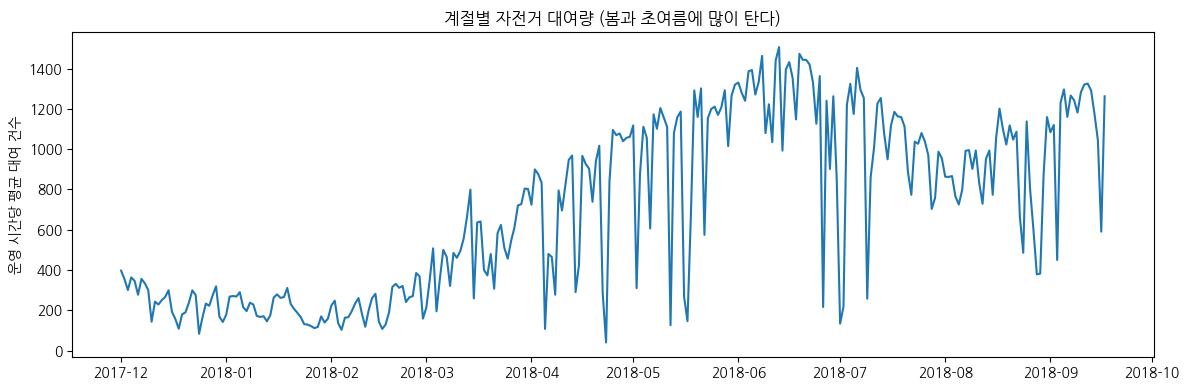

In [22]:
plt.figure(figsize=(12,4))
plt.plot(daily.index, daily.values) # 날짜, 평균_대여_수, 예: 2017-12-01  397.458333
plt.title("계절별 자전거 대여량 (봄과 초여름에 많이 탄다)")
plt.ylabel("운영 시간당 평균 대여 건수")
plt.tight_layout()
plt.show()

평일 피크: 18시, 주말 피크: 17시


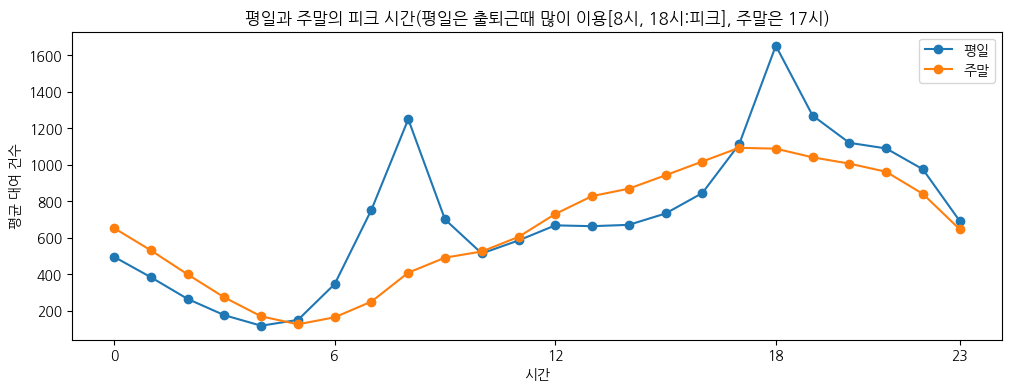

In [23]:
print(f"평일 피크: {weekday.idxmax()}시, 주말 피크: {weekend.idxmax()}시") # 평일 피크: 18시, 주말 피크: 17시
plt.figure(figsize=(12,4))
plt.plot(weekday.index, weekday.values, marker='o', label='평일')
plt.plot(weekend.index, weekend.values, marker='o', label='주말')
plt.title("평일과 주말의 피크 시간(평일은 출퇴근때 많이 이용[8시, 18시:피크], 주말은 17시)")
plt.xlabel("시간")
plt.ylabel("평균 대여 건수")
plt.legend()
plt.xticks( [0, 6, 12, 18, 23] )
plt.show()

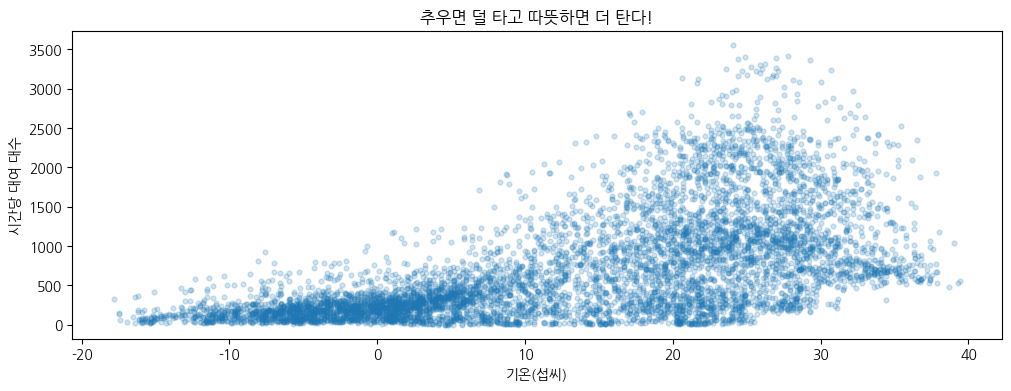

In [24]:
plt.figure(figsize=(12,4))
plt.scatter(eda['temp'], eda['bikes'], alpha=0.2, s=12)
plt.title("추우면 덜 타고 따뜻하면 더 탄다!")
plt.xlabel("기온(섭씨)")
plt.ylabel("시간당 대여 대수")
plt.show()

In [25]:
features = pd.DataFrame(index=df.index) # 날짜 기준으로 빈 DataFrame 준비

features['hour'] = df.index.hour
features['weekday'] = df.index.dayofweek # 월:0, .... 일:6
features['month'] = df.index.month

features['holiday'] = 0
features.loc[ df['Holiday'] == 'Holiday', 'holiday' ] = 1 # [ 행, 열] = 1

features['operating'] = 0
features.loc[ df['Functioning Day'] == 'Yes', 'operating' ] = 1

display(features.head())

,hour,weekday,month,holiday,operating
datetime,,,,,
2017-12-01 00:00:00,0,4,12,0,1
2017-12-01 01:00:00,1,4,12,0,1
2017-12-01 02:00:00,2,4,12,0,1
2017-12-01 03:00:00,3,4,12,0,1
2017-12-01 04:00:00,4,4,12,0,1


In [26]:
features['bikes_lag_1'] = df['bikes'].shift(1) # 한 시간 전 대여 수량
features['bikes_lag_24'] = df['bikes'].shift(24) # 하루 전
features['bikes_lag_168'] = df['bikes'].shift(168) # 24시간 * 7일 : 일주일 전
features

,hour,weekday,month,holiday,operating,bikes_lag_1,bikes_lag_24,bikes_lag_168
datetime,,,,,,,,
2017-12-01 00:00:00,0,4,12,0,1,NaN,NaN,NaN
2017-12-01 01:00:00,1,4,12,0,1,254.0,NaN,NaN
2017-12-01 02:00:00,2,4,12,0,1,204.0,NaN,NaN
2017-12-01 03:00:00,3,4,12,0,1,173.0,NaN,NaN
2017-12-01 04:00:00,4,4,12,0,1,107.0,NaN,NaN
...,...,...,...,...,...,...,...,...
2018-11-30 19:00:00,19,4,11,0,1,1384.0,1026.0,1007.0
2018-11-30 20:00:00,20,4,11,0,1,1003.0,818.0,767.0
2018-11-30 21:00:00,21,4,11,0,1,764.0,792.0,679.0


In [27]:
past_bikes = df['bikes'].shift(1)
features['bike_mean_24'] = past_bikes.rolling(24).mean() # 이동평균
features

,hour,weekday,month,holiday,operating,bikes_lag_1,bikes_lag_24,bikes_lag_168,bike_mean_24
datetime,,,,,,,,,
2017-12-01 00:00:00,0,4,12,0,1,NaN,NaN,NaN,NaN
2017-12-01 01:00:00,1,4,12,0,1,254.0,NaN,NaN,NaN
2017-12-01 02:00:00,2,4,12,0,1,204.0,NaN,NaN,NaN
2017-12-01 03:00:00,3,4,12,0,1,173.0,NaN,NaN,NaN
2017-12-01 04:00:00,4,4,12,0,1,107.0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
2018-11-30 19:00:00,19,4,11,0,1,1384.0,1026.0,1007.0,685.875000
2018-11-30 20:00:00,20,4,11,0,1,1003.0,818.0,767.0,684.916667
2018-11-30 21:00:00,21,4,11,0,1,764.0,792.0,679.0,682.666667


In [28]:
features['temp_lag_1'] = df['temp'].shift(1)
features['humidity_lag_1'] = df['humidity'].shift(1)
features['rain_lag_1'] = df['rain'].shift(1)

features

,hour,weekday,month,holiday,operating,bikes_lag_1,bikes_lag_24,bikes_lag_168,bike_mean_24,temp_lag_1,humidity_lag_1,rain_lag_1
datetime,,,,,,,,,,,,
2017-12-01 00:00:00,0,4,12,0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-12-01 01:00:00,1,4,12,0,1,254.0,NaN,NaN,NaN,-5.2,37.0,0.0
2017-12-01 02:00:00,2,4,12,0,1,204.0,NaN,NaN,NaN,-5.5,38.0,0.0
2017-12-01 03:00:00,3,4,12,0,1,173.0,NaN,NaN,NaN,-6.0,39.0,0.0
2017-12-01 04:00:00,4,4,12,0,1,107.0,NaN,NaN,NaN,-6.2,40.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
2018-11-30 19:00:00,19,4,11,0,1,1384.0,1026.0,1007.0,685.875000,4.7,34.0,0.0
2018-11-30 20:00:00,20,4,11,0,1,1003.0,818.0,767.0,684.916667,4.2,34.0,0.0
2018-11-30 21:00:00,21,4,11,0,1,764.0,792.0,679.0,682.666667,3.4,37.0,0.0


In [29]:
data = features.copy()
data['bikes'] = df['bikes']
data = data.iloc[168:].copy()
data = data.dropna()
data

,hour,weekday,month,holiday,operating,bikes_lag_1,bikes_lag_24,bikes_lag_168,bike_mean_24,temp_lag_1,humidity_lag_1,rain_lag_1,bikes
datetime,,,,,,,,,,,,,
2017-12-08 00:00:00,0,4,12,0,1,259.0,198.0,254.0,356.208333,-3.2,50.0,0.0,233
2017-12-08 01:00:00,1,4,12,0,1,233.0,218.0,204.0,357.666667,-3.5,49.0,0.0,230
2017-12-08 02:00:00,2,4,12,0,1,230.0,149.0,173.0,358.166667,-3.7,50.0,0.0,131
2017-12-08 03:00:00,3,4,12,0,1,131.0,102.0,107.0,357.416667,-4.3,53.0,0.0,99
2017-12-08 04:00:00,4,4,12,0,1,99.0,62.0,78.0,357.291667,-4.8,52.0,0.0,71
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2018-11-30 19:00:00,19,4,11,0,1,1384.0,1026.0,1007.0,685.875000,4.7,34.0,0.0,1003
2018-11-30 20:00:00,20,4,11,0,1,1003.0,818.0,767.0,684.916667,4.2,34.0,0.0,764
2018-11-30 21:00:00,21,4,11,0,1,764.0,792.0,679.0,682.666667,3.4,37.0,0.0,694


In [30]:
X = data.drop(columns='bikes')
y = data['bikes']

In [31]:
X

,hour,weekday,month,holiday,operating,bikes_lag_1,bikes_lag_24,bikes_lag_168,bike_mean_24,temp_lag_1,humidity_lag_1,rain_lag_1
datetime,,,,,,,,,,,,
2017-12-08 00:00:00,0,4,12,0,1,259.0,198.0,254.0,356.208333,-3.2,50.0,0.0
2017-12-08 01:00:00,1,4,12,0,1,233.0,218.0,204.0,357.666667,-3.5,49.0,0.0
2017-12-08 02:00:00,2,4,12,0,1,230.0,149.0,173.0,358.166667,-3.7,50.0,0.0
2017-12-08 03:00:00,3,4,12,0,1,131.0,102.0,107.0,357.416667,-4.3,53.0,0.0
2017-12-08 04:00:00,4,4,12,0,1,99.0,62.0,78.0,357.291667,-4.8,52.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
2018-11-30 19:00:00,19,4,11,0,1,1384.0,1026.0,1007.0,685.875000,4.7,34.0,0.0
2018-11-30 20:00:00,20,4,11,0,1,1003.0,818.0,767.0,684.916667,4.2,34.0,0.0
2018-11-30 21:00:00,21,4,11,0,1,764.0,792.0,679.0,682.666667,3.4,37.0,0.0


In [32]:
y

datetime
2017-12-08 00:00:00     233
2017-12-08 01:00:00     230
2017-12-08 02:00:00     131
2017-12-08 03:00:00      99
2017-12-08 04:00:00      71
                       ... 
2018-11-30 19:00:00    1003
2018-11-30 20:00:00     764
2018-11-30 21:00:00     694
2018-11-30 22:00:00     712
2018-11-30 23:00:00     584
Name: bikes, Length: 8592, dtype: int64

In [33]:
X_train = X.loc[ X.index < split_time ] # X의 앞의 80%
X_test = X.loc[ X.index >= split_time ] # X의 뒤의 20%
y_train = y.loc[ y.index < split_time ] # y의 앞의 80%
y_test = y.loc[ y.index >= split_time ] # y의 뒤의 20%
print(f"학습: {len(X_train):,}행 / 최종 평가: {len(X_test):,}행")

학습: 6,840행 / 최종 평가: 1,752행


In [34]:
X_train.head()

,hour,weekday,month,holiday,operating,bikes_lag_1,bikes_lag_24,bikes_lag_168,bike_mean_24,temp_lag_1,humidity_lag_1,rain_lag_1
datetime,,,,,,,,,,,,
2017-12-08 00:00:00,0,4,12,0,1,259.0,198.0,254.0,356.208333,-3.2,50.0,0.0
2017-12-08 01:00:00,1,4,12,0,1,233.0,218.0,204.0,357.666667,-3.5,49.0,0.0
2017-12-08 02:00:00,2,4,12,0,1,230.0,149.0,173.0,358.166667,-3.7,50.0,0.0
2017-12-08 03:00:00,3,4,12,0,1,131.0,102.0,107.0,357.416667,-4.3,53.0,0.0
2017-12-08 04:00:00,4,4,12,0,1,99.0,62.0,78.0,357.291667,-4.8,52.0,0.0


In [35]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

LinearRegression()

In [36]:
forest_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=8,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)
forest_model.fit(X_train, y_train)

RandomForestRegressor(max_depth=8, min_samples_leaf=5, n_jobs=-1,
                      random_state=42)

In [37]:
cv = TimeSeriesSplit(n_splits=3)
param_grid = {
    'max_depth': [ 8, None ],
    'min_samples_leaf': [ 1, 5 ]
}
base_forest = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

In [38]:
search = GridSearchCV(
    estimator=base_forest,
    param_grid=param_grid,
    cv=cv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)
search.fit(X_train, y_train)

GridSearchCV(cv=TimeSeriesSplit(gap=0, max_train_size=None, n_splits=3, test_size=None),
             estimator=RandomForestRegressor(n_jobs=-1, random_state=42),
             n_jobs=-1,
             param_grid={'max_depth': [8, None], 'min_samples_leaf': [1, 5]},
             scoring='neg_mean_absolute_error')

In [39]:
validation_mae = -search.best_score_
print("선택한 설정:", search.best_params_)

선택한 설정: {'max_depth': None, 'min_samples_leaf': 1}


In [40]:
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    max_depth=None,
    min_samples_leaf=1
)

In [41]:
print(f"시간순 교차감증 평균 MAE: {validation_mae:,.1f}건")

시간순 교차감증 평균 MAE: 178.1건


In [42]:
X_test

,hour,weekday,month,holiday,operating,bikes_lag_1,bikes_lag_24,bikes_lag_168,bike_mean_24,temp_lag_1,humidity_lag_1,rain_lag_1
datetime,,,,,,,,,,,,
2018-09-19 00:00:00,0,2,9,0,0,0.0,0.0,949.0,0.000000,21.2,69.0,0.0
2018-09-19 01:00:00,1,2,9,0,0,0.0,0.0,691.0,0.000000,21.0,66.0,0.0
2018-09-19 02:00:00,2,2,9,0,0,0.0,0.0,462.0,0.000000,20.5,64.0,0.0
2018-09-19 03:00:00,3,2,9,0,0,0.0,0.0,297.0,0.000000,20.0,70.0,0.0
2018-09-19 04:00:00,4,2,9,0,0,0.0,0.0,215.0,0.000000,19.7,70.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
2018-11-30 19:00:00,19,4,11,0,1,1384.0,1026.0,1007.0,685.875000,4.7,34.0,0.0
2018-11-30 20:00:00,20,4,11,0,1,1003.0,818.0,767.0,684.916667,4.2,34.0,0.0
2018-11-30 21:00:00,21,4,11,0,1,764.0,792.0,679.0,682.666667,3.4,37.0,0.0


In [43]:
baseline_pred = X_test['bikes_lag_1'] # 가짜, 이전 1시간값을 무조건 넣는다.
tunded_model = search.best_estimator_ # RandomForest 튜닝(GridSearch) 최적 모델

In [44]:
linear_pred = linear_model.predict(X_test)
forest_pred = forest_model.predict(X_test)
tuned_pred = tunded_model.predict(X_test)

In [45]:
# 0보다 작은 예측값은 0으로 바꾼다. 예 : -4 --> 0
linerar_pred = np.maximum(linear_pred, 0)
forest_pred = np.maximum(forest_pred, 0)
tuned_pred = np.maximum(tuned_pred, 0)

In [46]:
predictions = pd.DataFrame(index=X_test.index) # 날짜별 빈 DataFrame 준비
predictions['가짜 모델'] = baseline_pred
predictions['선형회귀'] = linear_pred
predictions['랜덤포레스트'] = forest_pred
predictions['튜닝'] = tuned_pred
predictions.head()

,가짜 모델,선형회귀,랜덤포레스트,튜닝
datetime,,,,
2018-09-19 00:00:00,0.0,-148.251732,182.502225,547.84
2018-09-19 01:00:00,0.0,-188.844737,156.236474,547.84
2018-09-19 02:00:00,0.0,-227.858833,156.236474,517.04
2018-09-19 03:00:00,0.0,-275.616776,154.634802,532.44
2018-09-19 04:00:00,0.0,-293.339235,154.634802,532.44


In [47]:
predictions.columns

Index(['가짜 모델', '선형회귀', '랜덤포레스트', '튜닝'], dtype='object')

In [48]:
results = [] # 채점 결과를 담을 빈 리스트 준비 

for model_name in predictions.columns:
    # print("model_name:", model_name)
    predicted = predictions[model_name]
    mae = mean_absolute_error(y_test, predicted)
    mse = mean_squared_error(y_test, predicted)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predicted)
    results.append({
        "모델": model_name,
        "MAE(건)": mae,
        "RMSE(건)": rmse,
        "R2": r2
    })

In [49]:
results

[{'모델': '가짜 모델',
  'MAE(건)': 192.30479452054794,
  'RMSE(건)': 299.2084839956534,
  'R2': 0.7620114409665266},
 {'모델': '선형회귀',
  'MAE(건)': 188.1700938121798,
  'RMSE(건)': 263.97774393922606,
  'R2': 0.8147565341860468},
 {'모델': '랜덤포레스트',
  'MAE(건)': 94.40893637672501,
  'RMSE(건)': 160.3621744184885,
  'R2': 0.9316384116396261},
 {'모델': '튜닝',
  'MAE(건)': 92.1442180365297,
  'RMSE(건)': 157.28605883637883,
  'R2': 0.9342359224629331}]

In [50]:
comparison = pd.DataFrame(results)
comparison = comparison.set_index('모델')
comparison.round(3)

,MAE(건),RMSE(건),R2
모델,,,
가짜 모델,192.305,299.208,0.762
선형회귀,188.170,263.978,0.815
랜덤포레스트,94.409,160.362,0.932
튜닝,92.144,157.286,0.934


In [51]:
base_mae = comparison.loc["가짜 모델", "MAE(건)" ] # 192.305
turned_mae = comparison.loc["튜닝", "MAE(건)"]      #  92.144

In [52]:
print(f"튜닝 모델은 시간당 평균 약 {turned_mae:,.1f}건 빗나갔습니다.")

튜닝 모델은 시간당 평균 약 92.1건 빗나갔습니다.


In [53]:
if base_mae > 0:
    improvement = 1 - ( turned_mae / base_mae ) # 1 - (92.144 / 192.305)
    print(f"가짜 대비 MAE 감소율: {improvement:.1%}")
else:
    print("가짜 예측의 MAE가 0이므로 감소율을 계산하지 않습니다.")

가짜 대비 MAE 감소율: 52.1%


In [54]:
recent_actual = y_test.tail(168) # 마지막 7일
recent_times = recent_actual.index
recent_predicted = predictions.loc[ recent_times, "튜닝" ]
recent_predicted

datetime
2018-11-24 00:00:00     484.28
2018-11-24 01:00:00     406.56
2018-11-24 02:00:00     355.67
2018-11-24 03:00:00     246.07
2018-11-24 04:00:00     192.96
                        ...   
2018-11-30 19:00:00    1054.27
2018-11-30 20:00:00     826.70
2018-11-30 21:00:00     792.80
2018-11-30 22:00:00     676.63
2018-11-30 23:00:00     587.88
Name: 튜닝, Length: 168, dtype: float64

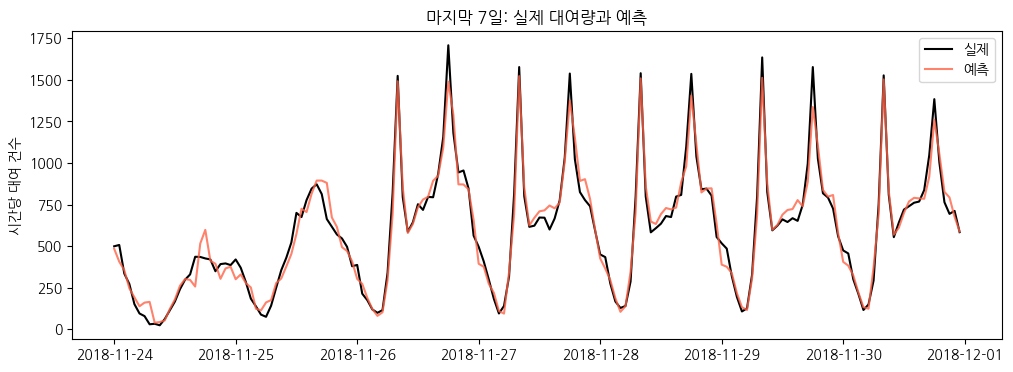

In [55]:
plt.figure(figsize=(12,4))
plt.plot(recent_times, recent_actual, label='실제', color='black')
plt.plot(recent_times, recent_predicted, label='예측', color='tomato', alpha=0.8)
plt.title("마지막 7일: 실제 대여량과 예측")
plt.ylabel("시간당 대여 건수")
plt.legend()
plt.show()

In [56]:
imp = pd.Series(tunded_model.feature_importances_, index=X.columns)
imp = imp.sort_values(ascending=False)
top8 = imp.head(8)
top8

bikes_lag_1       0.787281
bikes_lag_24      0.080264
bikes_lag_168     0.070181
hour              0.035143
temp_lag_1        0.008523
bike_mean_24      0.006311
humidity_lag_1    0.005121
weekday           0.004090
dtype: float64

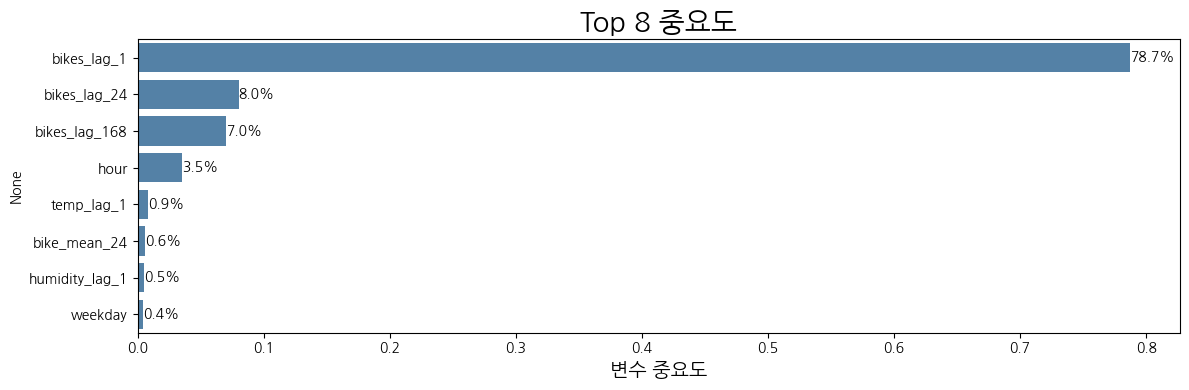

In [57]:
plt.figure(figsize=(12, 4))
ax = sns.barplot(x=top8.values, y=top8.index, color="steelblue")
for i in ax.containers:
    ax.bar_label(i, fmt="{:.1%}")
plt.title("Top 8 중요도", fontsize=20)
plt.xlabel("변수 중요도", fontsize=14)
plt.tight_layout()
plt.show()

In [58]:
# end